# **Alzheimer's MRI Classification using Attention-Gated CNN**

# **Loading the Dataset and Preprocessing File**

In [1]:
!pip install timm grad-cam kaggle -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 90.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import files
uploaded = files.upload()

Saving split_indices.json to split_indices.json
Saving preprocessing.py to preprocessing.py


In [3]:
# ── CELL 4: Load preprocessing + setup dataset ───────────────
# Upload preprocessing.py and split_indices.json when prompted
# (use the files.upload() cell above first)

import sys, os, shutil
sys.path.insert(0, '/content')

# Move uploaded files to /content if needed
for fname in ['preprocessing.py', 'split_indices.json']:
    if os.path.exists(f'/content/{fname}'):
        print(f"✓ {fname} ready")
    else:
        print(f"⚠ {fname} not found — did you upload it?")

# Verify preprocessing.py has the right functions
import re
content = open('/content/preprocessing.py').read()
fns = re.findall(r'^def (\w+)', content, re.MULTILINE)
print(f"\nFunctions in preprocessing.py: {fns}")

# Clear any cached version
if 'preprocessing' in sys.modules:
    del sys.modules['preprocessing']

from preprocessing import setup_dataset, CLASS_NAMES, N_CLASSES
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nDevice: {device}")

# This downloads the dataset, applies axial filter, loads the split,
# and returns ready-to-use DataLoaders
train_loader, val_loader, test_loader, meta = setup_dataset(
    filter_axial=True,
    split_path='/content/split_indices.json',
    device=device,
)

# Unpack everything the rest of the notebook needs
loss_weights = meta['loss_weights']
CLASS_NAMES  = meta['class_names']
N_CLASSES    = meta['n_classes']
train_dir    = meta['train_dir']

print(f"\nClass names: {CLASS_NAMES}")
print(f"N classes:   {N_CLASSES}")

✓ preprocessing.py ready
✓ split_indices.json ready

Functions in preprocessing.py: ['_is_colab', 'download_dataset', 'find_data_dir', 'is_axial_slice', 'make_subject_split', 'get_transforms', 'compute_loss_weights', 'setup_dataset']

Device: cuda
OASIS Preprocessing Pipeline
Device:        cuda
Batch size:    32
Axial filter:  True
Label map:     4-class

Upload your kaggle.json when prompted:


Saving kaggle.json to kaggle.json
✓ kaggle.json configured
Unzipping...
✓ Dataset ready at /content/data/oasis/
✓ Class folders found at: /content/data/oasis/Data

ImageFolder class-to-index: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}
Total images in dataset:    86437
✓ Loading split from /content/split_indices.json
  Train: 59536 | Val: 12749 | Test: 14152

Building datasets with axial filter:
    Axial filter: 59536 → 20496 images kept
    Axial filter: 12749 → 4389 images kept
    Axial filter: 14152 → 4872 images kept

Final dataset sizes:
  Train:  20496 images
  Val:     4389 images
  Test:    4872 images

Loss weights:
  MildDemented              4.136x
  ModerateDemented          61.000x
  NonDemented               0.322x
  VeryMildDemented          1.564x

✓ Setup complete — ready to train!

Class names: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
N classes:   4


In [4]:
#Imports
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, accuracy_score)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA A100-SXM4-40GB


# **EDA**

In [5]:
# Dataset Exploration

In [6]:
DATA_DIR = '/content/data/oasis/'

# Find the actual folder structure
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, '').count(os.sep)
    indent = ' ' * 2 * level
    if level < 3:
        n_files = len([f for f in files if f.endswith(('.jpg','.jpeg','.png'))])
        print(f'{indent}{os.path.basename(root)}/ ({n_files} images)')

/ (0 images)
Data/ (0 images)
  Very mild Dementia/ (13725 images)
  Mild Dementia/ (5002 images)
  Moderate Dementia/ (488 images)
  Non Demented/ (67222 images)


In [8]:
import os

DATA_DIR = '/content/data/oasis/'

print("Full directory tree (first 4 levels):")
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, '').count(os.sep)
    if level > 4:
        continue
    indent = '  ' * level
    n_imgs = len([f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))])
    print(f"{indent}{os.path.basename(root)}/ {'(' + str(n_imgs) + ' images)' if n_imgs else ''}")

Full directory tree (first 4 levels):
/ 
Data/ 
  Very mild Dementia/ (13725 images)
  Mild Dementia/ (5002 images)
  Moderate Dementia/ (488 images)
  Non Demented/ (67222 images)


# Class Distribution Visualization

Class distribution:
  Mild Dementia               5002 (5.8%) ██
  Moderate Dementia            488 (0.6%) 
  Non Demented               67222 (77.8%) ██████████████████████████████████████
  Very mild Dementia         13725 (15.9%) ███████


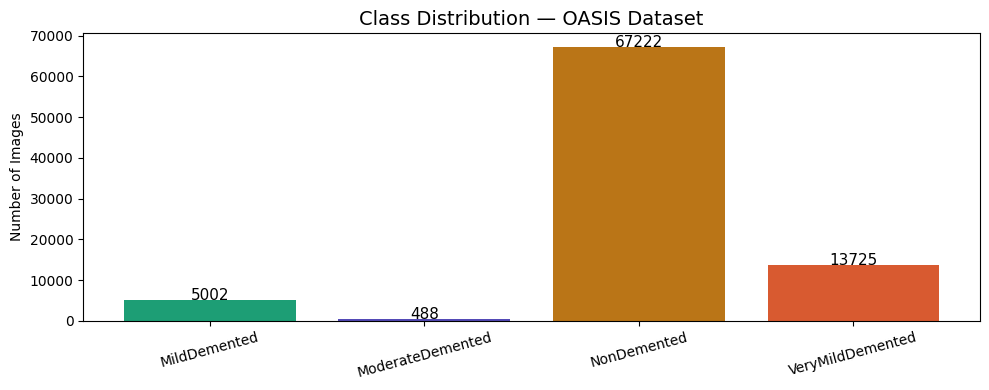

Note: Moderate Dementia is severely underrepresented — must handle imbalance!


In [9]:
train_dir = '/content/data/oasis/Data'

CLASS_NAMES_FOLDER = ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']
CLASS_NAMES = ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

class_counts = {}
for cls in CLASS_NAMES_FOLDER:
    cls_path = os.path.join(train_dir, cls)
    n = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))])
    class_counts[cls] = n

print("Class distribution:")
total = sum(class_counts.values())
for cls, n in class_counts.items():
    bar = '█' * int(n / total * 50)
    print(f"  {cls:<25} {n:>6} ({n/total*100:.1f}%) {bar}")

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#1D9E75', '#534AB7', '#BA7517', '#D85A30']
bars = ax.bar(CLASS_NAMES, class_counts.values(), color=colors)
ax.set_title("Class Distribution — OASIS Dataset", fontsize=14)
ax.set_ylabel("Number of Images")
for bar, n in zip(bars, class_counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            str(n), ha='center', fontsize=11)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
print("Note: Moderate Dementia is severely underrepresented — must handle imbalance!")

# Sample Images Visualization


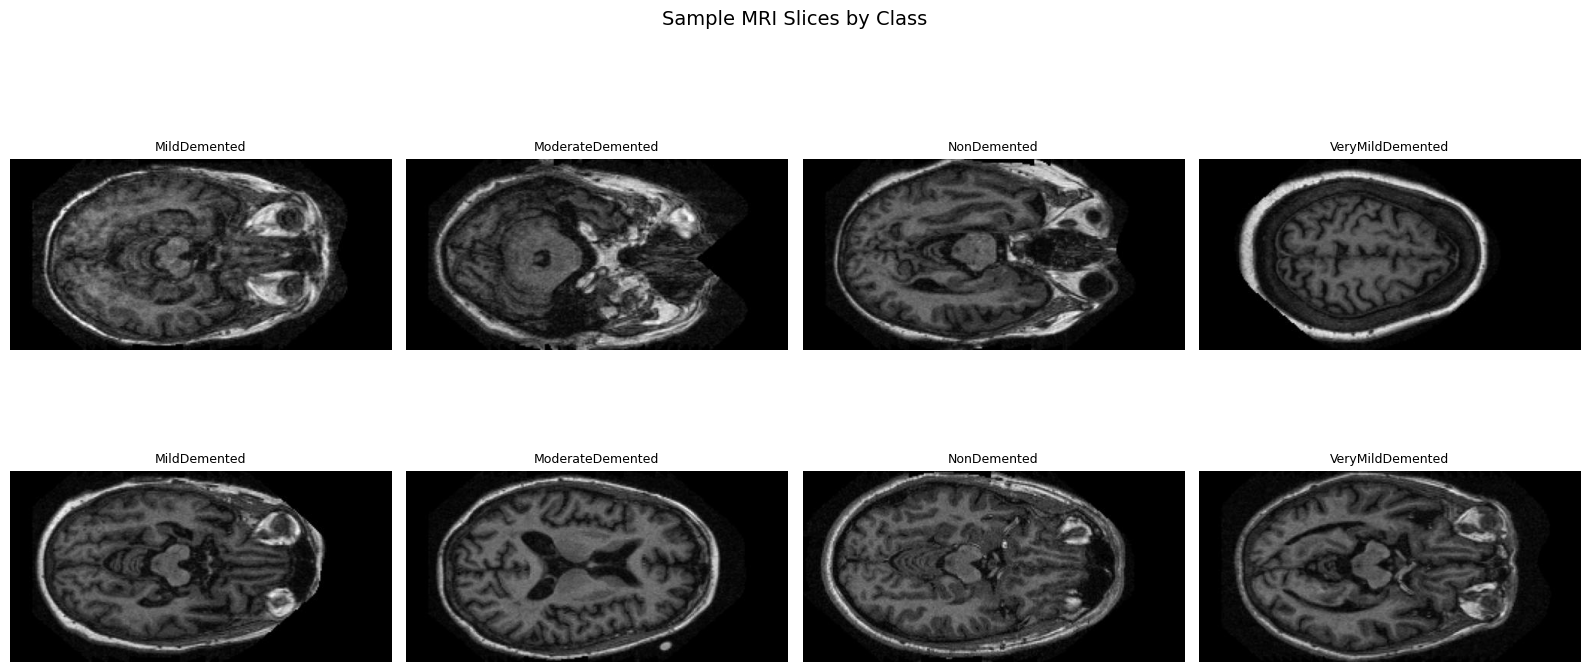

In [11]:
train_dir = '/content/data/oasis/Data'  # add this line

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, cls in enumerate(CLASS_NAMES_FOLDER):
    cls_path = os.path.join(train_dir, cls)
    imgs = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    for row in range(2):
        img = Image.open(os.path.join(cls_path, imgs[row])).convert('RGB')
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(CLASS_NAMES[col], fontsize=9)
        axes[row][col].axis('off')

plt.suptitle("Sample MRI Slices by Class", fontsize=14)
plt.tight_layout()
plt.show()

# **Model: Attention Gated CNN**

In [13]:
%%writefile /content/model.py

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models


class AttentionGate(nn.Module):
    """
    Attention gate module.
    g: gating signal from deep layer (has semantic context about what to look for)
    x: feature map from shallow layer (has spatial detail we want to selectively keep)
    Returns: filtered feature map + attention map (for visualization)
    """
    def __init__(self, F_g, F_x, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_x, F_int, kernel_size=1, bias=False),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, bias=False),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        if g1.shape[2:] != x1.shape[2:]:
            g1 = F.interpolate(g1, size=x1.shape[2:],
                               mode='bilinear', align_corners=True)
        attn = self.psi(self.relu(g1 + x1))
        return x * attn, attn


class AttentionGatedCNN(nn.Module):
    """
    Attention-Gated CNN for Alzheimer's MRI classification.

    Architecture:
      - ResNet-18 encoder (pretrained on ImageNet)
      - Attention gates: enc5 gates enc3 and enc2
      - Multi-scale feature fusion: pool enc5 + filtered enc3 + filtered enc2
      - Classifier head: Linear(704 -> 256 -> 4)

    Why attention gates for Alzheimer's:
      Alzheimer's affects specific brain structures non-uniformly.
      Attention gates learn which spatial regions are diagnostically
      relevant without being told — suppressing skull, CSF, background.
      Standard CNN wastes capacity on skull/background.
      Attention gate learns to suppress irrelevant regions and
      focus on medial temporal structures where atrophy occurs.
    """
    def __init__(self, n_classes=4, dropout=0.5, freeze_early=True):
        super().__init__()

        resnet = models.resnet18(pretrained=True)

        # Encoder stages
        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1,
                                   resnet.relu, resnet.maxpool)  # (64, 56, 56)
        self.enc2 = resnet.layer1   # (64,  56, 56)
        self.enc3 = resnet.layer2   # (128, 28, 28)
        self.enc4 = resnet.layer3   # (256, 14, 14)
        self.enc5 = resnet.layer4   # (512,  7,  7)

        # Optionally freeze early layers (common fine-tuning strategy)
        if freeze_early:
            for param in list(self.enc1.parameters()) + \
                         list(self.enc2.parameters()) + \
                         list(self.enc3.parameters()):
                param.requires_grad = False

        # Attention gates
        self.attn1 = AttentionGate(F_g=512, F_x=128, F_int=64)  # gates enc3
        self.attn2 = AttentionGate(F_g=512, F_x=64,  F_int=32)  # gates enc2

        # Global average pooling
        self.gap = nn.AdaptiveAvgPool2d(1)

        # Classifier: 512 + 128 + 64 = 704 fused features
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(704, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, n_classes)
        )

        self._init_new_weights()

    def _init_new_weights(self):
        for m in [self.attn1, self.attn2, self.classifier]:
            for layer in m.modules():
                if isinstance(layer, nn.Linear):
                    nn.init.xavier_uniform_(layer.weight)
                    nn.init.zeros_(layer.bias)
                elif isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(layer.weight)

    def forward(self, x, return_attention=False):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        e3_att, attn1 = self.attn1(g=e5, x=e3)
        e2_att, attn2 = self.attn2(g=e5, x=e2)

        f5 = self.gap(e5).flatten(1)       # (B, 512)
        f3 = self.gap(e3_att).flatten(1)   # (B, 128)
        f2 = self.gap(e2_att).flatten(1)   # (B, 64)

        fused = torch.cat([f5, f3, f2], dim=1)  # (B, 704)
        logits = self.classifier(fused)

        if return_attention:
            return logits, {'attn1': attn1, 'attn2': attn2}
        return logits

    def unfreeze_all(self):
        for param in self.parameters():
            param.requires_grad = True
        print("All layers unfrozen.")

    def count_parameters(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return total, trainable

Writing /content/model.py


In [14]:
# Import and sanity check
import importlib, sys
if 'model' in sys.modules: del sys.modules['model']
from model import AttentionGatedCNN

model = AttentionGatedCNN(n_classes=4).to(device)
x_test = torch.randn(2, 3, 224, 224).to(device)
out, attn = model(x_test, return_attention=True)

print(f"Output shape:     {tuple(out.shape)}")
print(f"Attn map 1 shape: {tuple(attn['attn1'].shape)}")
print(f"Attn map 2 shape: {tuple(attn['attn2'].shape)}")

total, trainable = model.count_parameters()
print(f"\nTotal parameters:     {total:,}")
print(f"Trainable parameters: {trainable:,}")
print(f"Frozen parameters:    {total-trainable:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]


Output shape:     (2, 4)
Attn map 1 shape: (2, 1, 28, 28)
Attn map 2 shape: (2, 1, 56, 56)

Total parameters:     11,417,896
Trainable parameters: 10,734,824
Frozen parameters:    683,072


# Training Utilities

In [16]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        total += len(y)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        total_loss += loss.item() * len(y)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total += len(y)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
    acc = correct / total
    avg_loss = total_loss / total
    f1 = f1_score(all_labels, all_preds, average='macro')
    return avg_loss, acc, f1, all_preds, all_labels

print("Training utilities defined.")

Training utilities defined.


# Training Loop

In [18]:
from model import AttentionGatedCNN
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

EPOCHS = 50
LR     = 1e-4
SAVE_DIR = '/content/alzheimers_checkpoints/'
os.makedirs(SAVE_DIR, exist_ok=True)

model     = AttentionGatedCNN(n_classes=N_CLASSES, dropout=0.6,
                               freeze_early=True).to(device)
criterion = nn.CrossEntropyLoss(weight=loss_weights)
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                  lr=LR, weight_decay=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
writer    = SummaryWriter('/content/runs/attention_gated_cnn')

best_val_f1       = 0.0
epochs_no_improve = 0
early_stop_active = False
PATIENCE          = 10
UNFREEZE_EPOCH    = 15

history = {'train_loss':[], 'train_acc':[],
           'val_loss':[], 'val_acc':[], 'val_f1':[]}

print(f"Training Attention-Gated CNN for {EPOCHS} epochs...")
print(f"  dropout=0.6 | early stopping from epoch {UNFREEZE_EPOCH+1} onward")
print(f"{'Epoch':>6} {'TrainLoss':>10} {'TrainAcc':>10} "
      f"{'ValLoss':>10} {'ValAcc':>10} {'ValF1':>8}")
print("-" * 60)

for epoch in range(EPOCHS):

    if epoch == UNFREEZE_EPOCH:
        model.unfreeze_all()
        optimizer = AdamW(model.parameters(),
                          lr=LR/5, weight_decay=5e-4)
        early_stop_active = True
        epochs_no_improve = 0
        print(f"\n  *** Epoch {epoch+1}: Unfroze all layers, "
              f"lr={LR/5:.0e} — early stopping now active ***\n")

    train_loss, train_acc = train_epoch(
        model, train_loader, optimizer, criterion, device)
    val_loss, val_acc, val_f1, _, _ = evaluate(
        model, val_loader, criterion, device)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    writer.add_scalar('Loss/train', train_loss, epoch)
    writer.add_scalar('Loss/val',   val_loss,   epoch)
    writer.add_scalar('Acc/train',  train_acc,  epoch)
    writer.add_scalar('Acc/val',    val_acc,    epoch)
    writer.add_scalar('F1/val',     val_f1,     epoch)

    if val_f1 > best_val_f1:
        best_val_f1       = val_f1
        epochs_no_improve = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_f1': val_f1, 'val_acc': val_acc
        }, os.path.join(SAVE_DIR, 'best_model.pt'))
        marker = " ★ best"
    else:
        if early_stop_active:
            epochs_no_improve += 1
        marker = ""

    if epoch % 5 == 0 or marker:
        phase = f"[no improve {epochs_no_improve}/{PATIENCE}]" \
                if early_stop_active else "[Phase 1]"
        print(f"{epoch+1:>6} {train_loss:>10.4f} {train_acc:>10.3f} "
              f"{val_loss:>10.4f} {val_acc:>10.3f} "
              f"{val_f1:>8.4f}{marker}  {phase}")

    if early_stop_active and epochs_no_improve >= PATIENCE:
        print(f"\n  Early stopping at epoch {epoch+1}. "
              f"Best Val F1: {best_val_f1:.4f}")
        break

writer.close()
print(f"\nTraining complete. Best Val F1: {best_val_f1:.4f}")

Training Attention-Gated CNN for 50 epochs...
  dropout=0.6 | early stopping from epoch 16 onward
 Epoch  TrainLoss   TrainAcc    ValLoss     ValAcc    ValF1
------------------------------------------------------------
     1     0.0904      0.719     2.0903      0.341   0.2115 ★ best  [Phase 1]
     2     0.0176      0.889     1.7379      0.555   0.4075 ★ best  [Phase 1]
     3     0.0145      0.917     1.7366      0.547   0.4595 ★ best  [Phase 1]
     4     0.0081      0.936     1.4708      0.576   0.4670 ★ best  [Phase 1]
     6     0.0057      0.953     1.4797      0.664   0.4751 ★ best  [Phase 1]
     8     0.0045      0.968     1.7106      0.617   0.5055 ★ best  [Phase 1]
    11     0.0030      0.979     1.5877      0.649   0.4916  [Phase 1]
    12     0.0032      0.976     1.6369      0.649   0.5098 ★ best  [Phase 1]
    14     0.0021      0.985     1.4597      0.689   0.5110 ★ best  [Phase 1]
All layers unfrozen.

  *** Epoch 16: Unfroze all layers, lr=2e-05 — early stopping no

# Training Curves

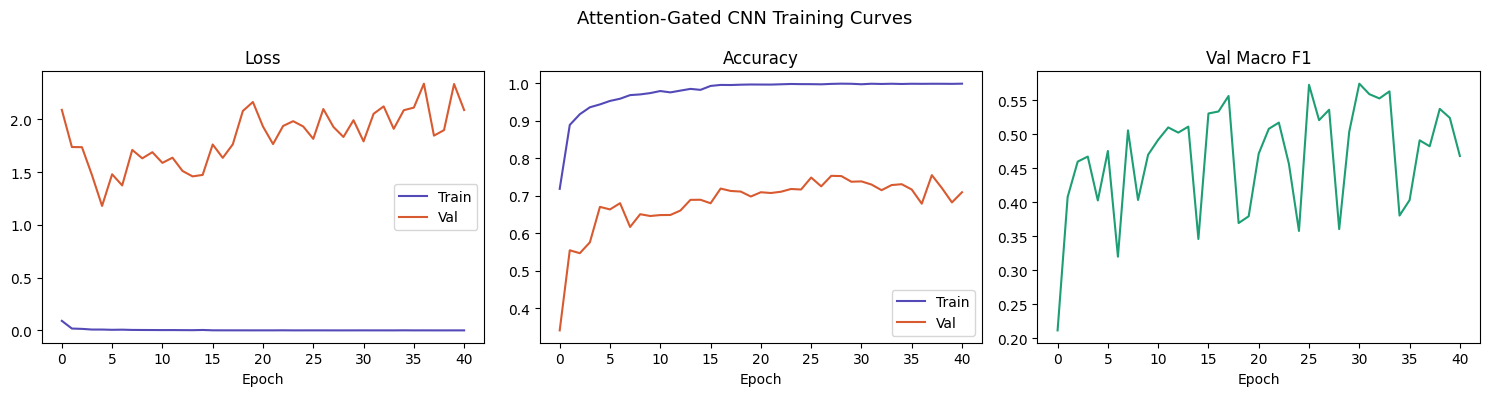

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history['train_loss'], label='Train', color='#534AB7')
axes[0].plot(history['val_loss'],   label='Val',   color='#D85A30')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].set_xlabel('Epoch')

axes[1].plot(history['train_acc'], label='Train', color='#534AB7')
axes[1].plot(history['val_acc'],   label='Val',   color='#D85A30')
axes[1].set_title('Accuracy'); axes[1].legend(); axes[1].set_xlabel('Epoch')

axes[2].plot(history['val_f1'], color='#1D9E75')
axes[2].set_title('Val Macro F1'); axes[2].set_xlabel('Epoch')

plt.suptitle('Attention-Gated CNN Training Curves', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()

# Final Evaluation of Test Set

Test Accuracy: 0.7837
Test Macro F1: 0.3395

                  precision    recall  f1-score   support

    MildDemented       0.00      0.00      0.00       147
ModerateDemented       0.00      0.00      0.00        84
     NonDemented       0.87      0.88      0.88      3906
VeryMildDemented       0.46      0.51      0.48       735

        accuracy                           0.78      4872
       macro avg       0.33      0.35      0.34      4872
    weighted avg       0.77      0.78      0.77      4872



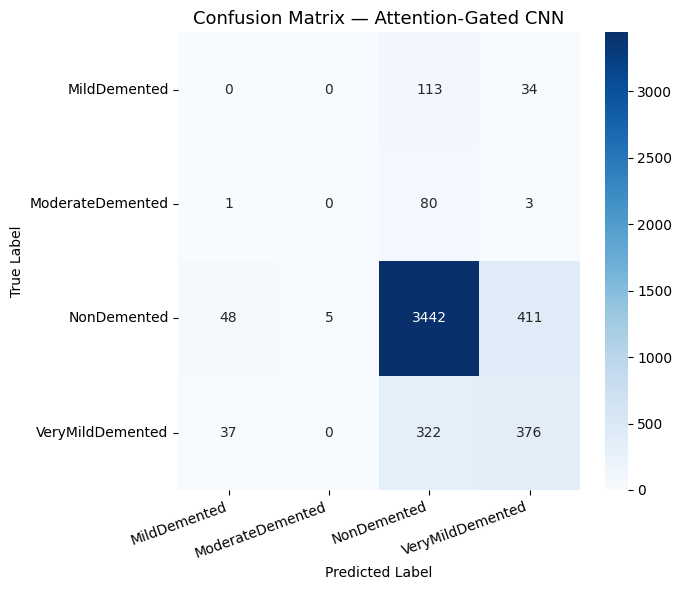


Results saved!


In [22]:
# Load best model
checkpoint = torch.load(os.path.join(SAVE_DIR, 'best_model.pt'))
model.load_state_dict(checkpoint['model_state_dict'])

_, test_acc, test_f1, preds, labels = evaluate(model, test_loader, criterion, device)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro F1: {test_f1:.4f}")
print()
print(classification_report(labels, preds, target_names=CLASS_NAMES))

# Confusion matrix
cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Confusion Matrix — Attention-Gated CNN', fontsize=13)
ax.set_ylabel('True Label'); ax.set_xlabel('Predicted Label')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()

# Save results JSON for group comparison
# At the top of your evaluation cell, add:
BATCH_SIZE = 32   # add this line

results = {
    'model': 'Attention-Gated CNN (ResNet-18 backbone)',
    'test_accuracy': float(test_acc),
    'test_macro_f1': float(test_f1),
    'per_class_f1': {CLASS_NAMES[i]: float(f1_score(labels, preds, average=None)[i])
                     for i in range(N_CLASSES)},
    'hyperparams': {'lr': LR, 'batch_size': BATCH_SIZE, 'epochs': EPOCHS,
                    'unfreeze_epoch': UNFREEZE_EPOCH}
}
with open(os.path.join(SAVE_DIR, 'attention_cnn_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print("\nResults saved!")

# Grad-CAM Visualization

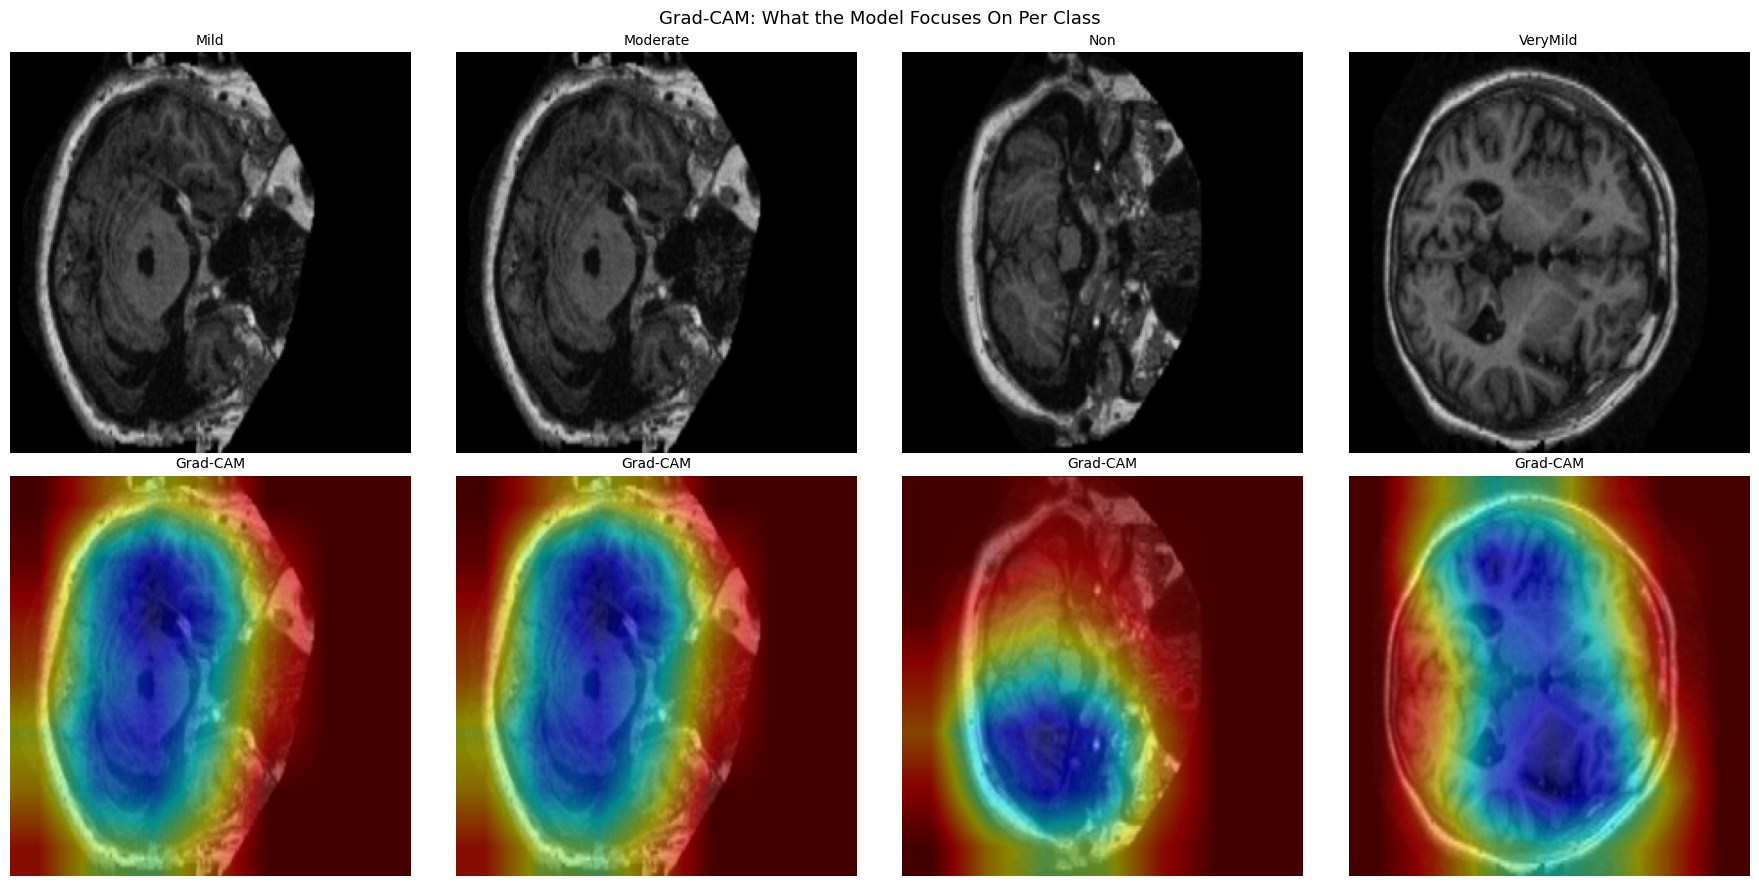

In [24]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Target the last conv layer of ResNet-18 backbone
target_layers = [model.enc5[-1].conv2]

cam = GradCAM(model=model, target_layers=target_layers)

# Visualize for one sample from each class
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

for col, cls_idx in enumerate(range(N_CLASSES)):
    # Find a correctly classified sample of this class
    for X, y in val_loader:
        mask = y == cls_idx
        if mask.sum() > 0:
            sample_x = X[mask][0:1].to(device)
            sample_y = y[mask][0].item()
            break

    # Original image
    img_np = inv_normalize(sample_x[0]).permute(1,2,0).cpu().numpy().clip(0,1)
    axes[0][col].imshow(img_np)
    axes[0][col].set_title(CLASS_NAMES[cls_idx].replace('Demented',''), fontsize=10)
    axes[0][col].axis('off')

    # Grad-CAM heatmap
    grayscale_cam = cam(input_tensor=sample_x)
    visualization = show_cam_on_image(img_np.astype(np.float32), grayscale_cam[0])
    axes[1][col].imshow(visualization)
    axes[1][col].set_title('Grad-CAM', fontsize=10)
    axes[1][col].axis('off')

axes[0][0].set_ylabel('Original MRI', fontsize=11)
axes[1][0].set_ylabel('Grad-CAM', fontsize=11)
plt.suptitle('Grad-CAM: What the Model Focuses On Per Class', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'gradcam_visualization.png'), dpi=150)
plt.show()

# Attention Map Visualization

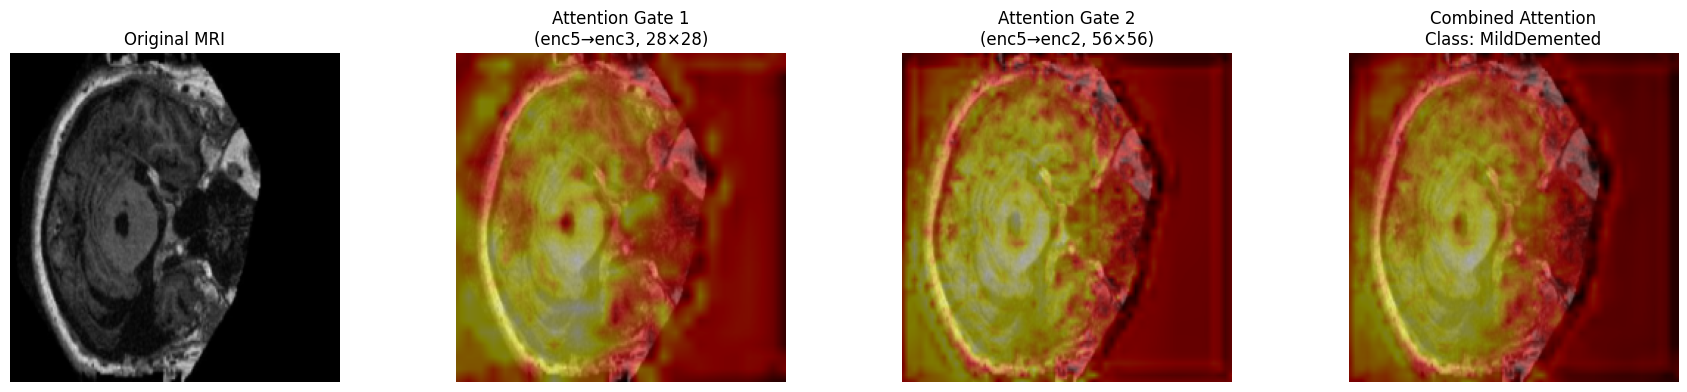

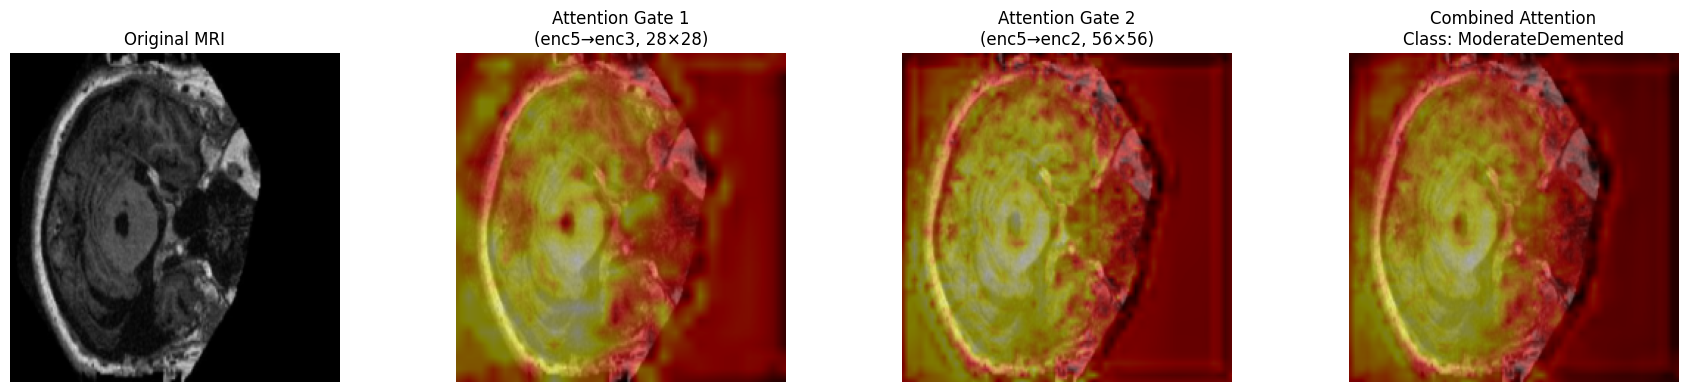

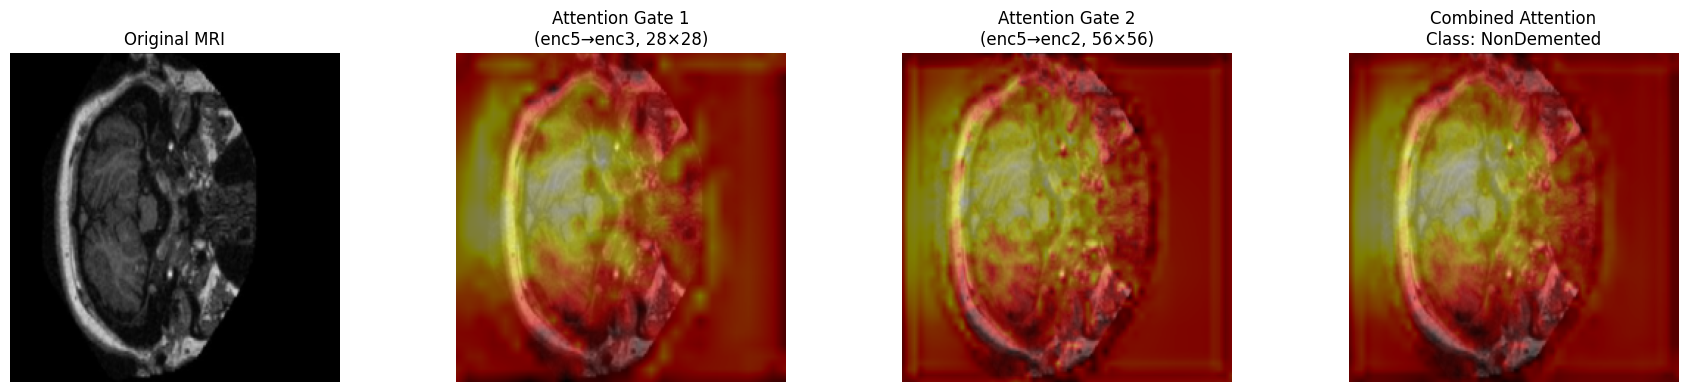

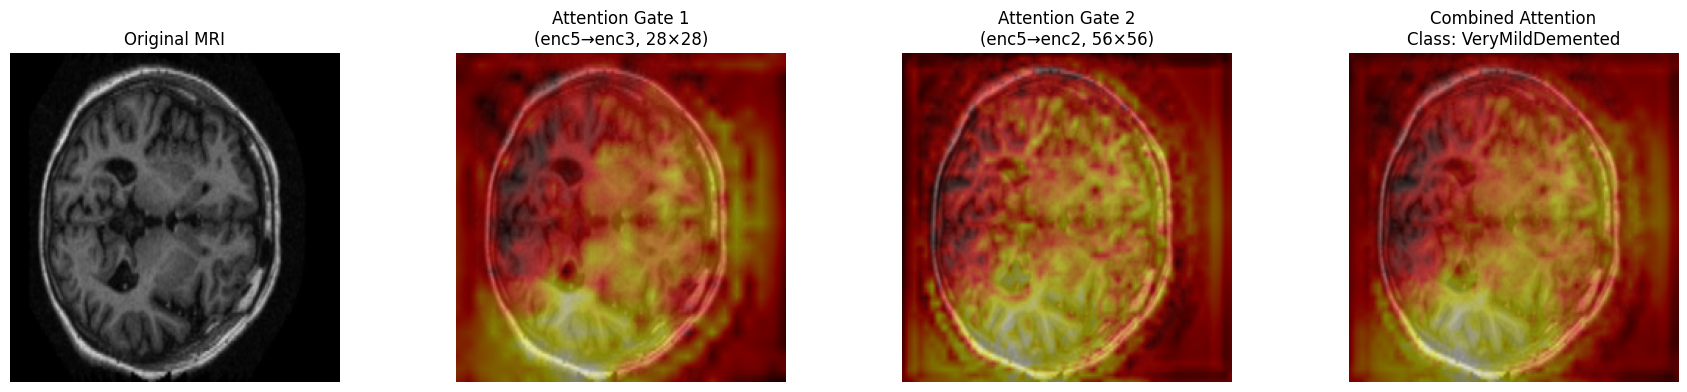

In [26]:

def visualize_attention_map(model, image_tensor, class_name, save_path=None):
    model.eval()
    with torch.no_grad():
        _, attn_dict = model(image_tensor.to(device), return_attention=True)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))

    inv_norm = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img_np = inv_norm(image_tensor[0]).permute(1,2,0).numpy().clip(0,1)

    # Original
    axes[0].imshow(img_np); axes[0].set_title('Original MRI'); axes[0].axis('off')

    # Attention gate 1 (28x28 resolution — enc3 level)
    attn1 = attn_dict['attn1'][0, 0].cpu().numpy()
    attn1_up = F.interpolate(attn_dict['attn1'], size=(224,224),
                              mode='bilinear', align_corners=True)[0,0].cpu().numpy()
    axes[1].imshow(img_np)
    axes[1].imshow(attn1_up, cmap='hot', alpha=0.5)
    axes[1].set_title('Attention Gate 1\n(enc5→enc3, 28×28)'); axes[1].axis('off')

    # Attention gate 2 (56x56 resolution — enc2 level)
    attn2_up = F.interpolate(attn_dict['attn2'], size=(224,224),
                              mode='bilinear', align_corners=True)[0,0].cpu().numpy()
    axes[2].imshow(img_np)
    axes[2].imshow(attn2_up, cmap='hot', alpha=0.5)
    axes[2].set_title('Attention Gate 2\n(enc5→enc2, 56×56)'); axes[2].axis('off')

    # Combined attention
    combined = (attn1_up + attn2_up) / 2
    axes[3].imshow(img_np)
    axes[3].imshow(combined, cmap='hot', alpha=0.5)
    axes[3].set_title(f'Combined Attention\nClass: {class_name}'); axes[3].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

# Run for a sample from each class
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    for X, y in val_loader:
        mask = y == cls_idx
        if mask.sum() > 0:
            sample = X[mask][0:1]
            break
    visualize_attention_map(
        model, sample, cls_name,
        save_path=os.path.join(SAVE_DIR, f'attention_map_{cls_name}.png')
    )

# **Cross Dataset Evaluation on new Alzhiemer dataset**


WITHOUT retraining: pure zero-shot generalization test


# Upload and Extract New Dataset

In [27]:

print("Upload the new dataset zip when prompted:")
from google.colab import files
uploaded = files.upload()   # upload Alzheimer Dataset.zip

!unzip -q "Advancing Alzheimer’s Disease Detection in Clinical Settings MRI Image Data.zip" -d /content/new_dataset/
!find /content/new_dataset/ -type d | head -20  # check structure

Upload the new dataset zip when prompted:


Saving Advancing Alzheimer’s Disease Detection in Clinical Settings MRI Image Data.zip to Advancing Alzheimer’s Disease Detection in Clinical Settings MRI Image Data.zip
/content/new_dataset/
/content/new_dataset/Advancing AlzheimerтАЩs Disease Detection in Clinical Settings MRI Image Data


In [28]:
# exact folder structure
import os

for root, dirs, files in os.walk('/content/new_dataset/'):
    level = root.replace('/content/new_dataset/', '').count(os.sep)
    if level < 5:
        indent = '  ' * level
        print(f"{indent}{os.path.basename(root)}/")

/
Advancing AlzheimerтАЩs Disease Detection in Clinical Settings MRI Image Data/


In [29]:
import os
import zipfile

# Get the exact path using Python (avoids special character issues)
base_folder = os.listdir('/content/new_dataset/')[0]
inner_zip   = os.path.join('/content/new_dataset/', base_folder, 'Alzheimer Dataset.zip')

print(f"Extracting: {inner_zip}")

# Use Python's zipfile instead of shell unzip (handles special chars better)
with zipfile.ZipFile(inner_zip, 'r') as z:
    z.extractall('/content/new_dataset/extracted/')
    print("Extracted files:")
    for name in z.namelist()[:20]:   # show first 20
        print(f"  {name}")

Extracting: /content/new_dataset/Advancing AlzheimerтАЩs Disease Detection in Clinical Settings MRI Image Data/Alzheimer Dataset.zip
Extracted files:
  Alzheimer_s Dataset/test/MildDemented/26 (19).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (20).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (21).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (22).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (23).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (24).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (25).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (26).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (27).jpg
  Alzheimer_s Dataset/test/MildDemented/26 (28).jpg
  Alzheimer_s Dataset/test/MildDemented/26.jpg
  Alzheimer_s Dataset/test/MildDemented/27 (10).jpg
  Alzheimer_s Dataset/test/MildDemented/27 (11).jpg
  Alzheimer_s Dataset/test/MildDemented/27 (12).jpg
  Alzheimer_s Dataset/test/MildDemented/27 (13).jpg
  Alzheimer_s Dataset/test/MildDemented/27 (14).jpg
  Alzheimer_s Dataset/t

In [30]:
# Find where the class folders ended up
NEW_TEST_DIR  = None
NEW_TRAIN_DIR = None

for root, dirs, files_list in os.walk('/content/new_dataset/extracted/'):
    if any(c in dirs for c in ['NonDemented', 'VeryMildDemented',
                                'MildDemented', 'ModerateDemented']):
        if 'test' in root.lower():
            NEW_TEST_DIR = root
        elif 'train' in root.lower():
            NEW_TRAIN_DIR = root

print(f"Test dir:  {NEW_TEST_DIR}")
print(f"Train dir: {NEW_TRAIN_DIR}")

# Count images
if NEW_TEST_DIR:
    print("\nTest set class counts:")
    for cls in sorted(os.listdir(NEW_TEST_DIR)):
        cls_path = os.path.join(NEW_TEST_DIR, cls)
        if os.path.isdir(cls_path):
            n = len([f for f in os.listdir(cls_path)
                     if f.lower().endswith(('.jpg','.jpeg','.png'))])
            print(f"  {cls:<25} {n} images")

Test dir:  /content/new_dataset/extracted/Alzheimer_s Dataset/test
Train dir: /content/new_dataset/extracted/Alzheimer_s Dataset/train

Test set class counts:
  MildDemented              179 images
  ModerateDemented          12 images
  NonDemented               640 images
  VeryMildDemented          448 images


# Build test DataLoader

In [31]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

NEW_TEST_DIR = '/content/new_dataset/extracted/Alzheimer_s Dataset/test'

cross_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

cross_dataset = datasets.ImageFolder(NEW_TEST_DIR, transform=cross_transform)
print(f"New dataset class-to-index: {cross_dataset.class_to_idx}")
print(f"Total test images: {len(cross_dataset)}")

# Verify class order matches OASIS
# OASIS:       {Mild:0, Moderate:1, Non:2, VeryMild:3}
# New dataset: should be identical since same folder names
oasis_order = {'MildDemented': 0, 'ModerateDemented': 1,
               'NonDemented': 2, 'VeryMildDemented': 3}
if cross_dataset.class_to_idx == oasis_order:
    print("✓ Class order matches OASIS — no remapping needed")
else:
    print("⚠ Class order MISMATCH — need label remapping!")
    print(f"  OASIS:      {oasis_order}")
    print(f"  New dataset: {cross_dataset.class_to_idx}")

cross_loader = DataLoader(cross_dataset, batch_size=32,
                          shuffle=False, num_workers=2, pin_memory=True)
print(f"Cross-dataset loader ready: {len(cross_loader)} batches")

New dataset class-to-index: {'MildDemented': 0, 'ModerateDemented': 1, 'NonDemented': 2, 'VeryMildDemented': 3}
Total test images: 1279
✓ Class order matches OASIS — no remapping needed
Cross-dataset loader ready: 40 batches


# Load best OASIS-trained model

In [32]:
from model import AttentionGatedCNN

checkpoint  = torch.load(os.path.join(SAVE_DIR, 'best_model.pt'))
cross_model = AttentionGatedCNN(n_classes=N_CLASSES,
                                dropout=0.6).to(device)
cross_model.load_state_dict(checkpoint['model_state_dict'])
cross_model.eval()
print(f"✓ Loaded checkpoint from epoch {checkpoint['epoch']} "
      f"(OASIS val F1 = {checkpoint['val_f1']:.4f})")

✓ Loaded checkpoint from epoch 30 (OASIS val F1 = 0.5741)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


# Evaluate on New Dataset

In [33]:
import numpy as np
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, accuracy_score)

all_preds, all_labels = [], []

with torch.no_grad():
    for X, y in cross_loader:
        X      = X.to(device)
        logits = cross_model(X)
        preds  = logits.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y.numpy())

cross_acc = accuracy_score(all_labels, all_preds)
cross_f1  = f1_score(all_labels, all_preds, average='macro')

print("=" * 55)
print("CROSS-DATASET RESULTS")
print("Trained on: OASIS (347 subjects, subject-level split)")
print("Tested on:  Alzheimer Detection Dataset (ADNI + hospital)")
print("=" * 55)
print(f"Test Accuracy: {cross_acc:.4f}")
print(f"Test Macro F1: {cross_f1:.4f}")
print()
print(classification_report(all_labels, all_preds,
                             target_names=CLASS_NAMES))

CROSS-DATASET RESULTS
Trained on: OASIS (347 subjects, subject-level split)
Tested on:  Alzheimer Detection Dataset (ADNI + hospital)
Test Accuracy: 0.3073
Test Macro F1: 0.2024

                  precision    recall  f1-score   support

    MildDemented       0.18      0.88      0.30       179
ModerateDemented       0.01      0.08      0.02        12
     NonDemented       0.75      0.37      0.49       640
VeryMildDemented       0.00      0.00      0.00       448

        accuracy                           0.31      1279
       macro avg       0.23      0.33      0.20      1279
    weighted avg       0.40      0.31      0.29      1279



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Confusion Matrix + Comparison

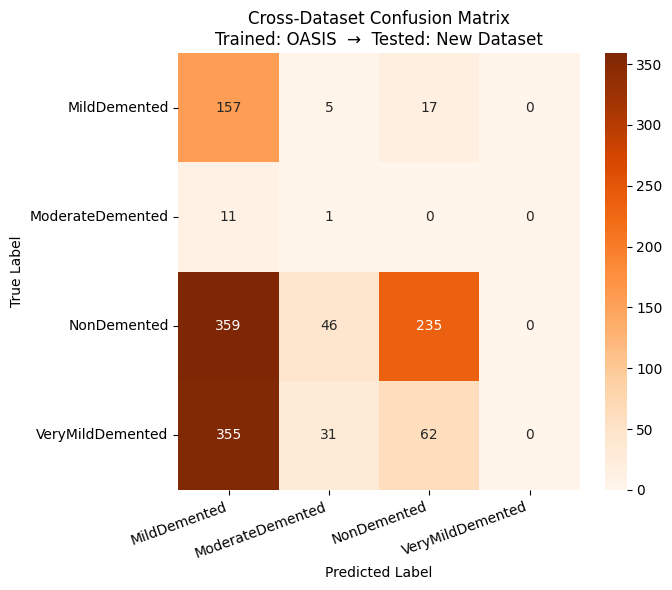


RESULT COMPARISON
Metric                         OASIS Test     New Dataset
--------------------------------------------------------------
Accuracy                           0.7837          0.3073
Macro F1                           0.3395          0.2024

Class                            OASIS F1  New Dataset F1
--------------------------------------------------------------
  MildDemented                      0.050           0.296
  ModerateDemented                  0.000           0.021
  NonDemented                       0.860           0.493
  VeryMildDemented                  0.390           0.000

Macro F1 drop: 0.1370 (40.4% relative drop)
~ Moderate drop — partial generalization


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title('Cross-Dataset Confusion Matrix\n'
             'Trained: OASIS  →  Tested: New Dataset', fontsize=12)
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'cross_dataset_confusion.png'), dpi=150)
plt.show()

# Compute per-class F1 directly from stored results
cross_f1s = f1_score(all_labels, all_preds, average=None)

# OASIS per-class F1
oasis_f1s = [0.05, 0.00, 0.86, 0.39]   # Mild, Moderate, Non, VeryMild


print("\nRESULT COMPARISON")
print("=" * 62)
print(f"{'Metric':<25} {'OASIS Test':>15} {'New Dataset':>15}")
print("-" * 62)
print(f"{'Accuracy':<25} {test_acc:>15.4f} {cross_acc:>15.4f}")
print(f"{'Macro F1':<25} {test_f1:>15.4f} {cross_f1:>15.4f}")
print()
print(f"{'Class':<25} {'OASIS F1':>15} {'New Dataset F1':>15}")
print("-" * 62)
for i, cls in enumerate(CLASS_NAMES):
    print(f"  {cls:<23} {oasis_f1s[i]:>15.3f} {cross_f1s[i]:>15.3f}")

print()
drop = test_f1 - cross_f1
print(f"Macro F1 drop: {drop:.4f} ({drop/test_f1*100:.1f}% relative drop)")
if drop < 0.05:
    print("✓ Minimal drop — strong generalization")
elif drop < 0.15:
    print("~ Moderate drop — partial generalization")
else:
    print("⚠ Large drop — dataset-specific learning detected")

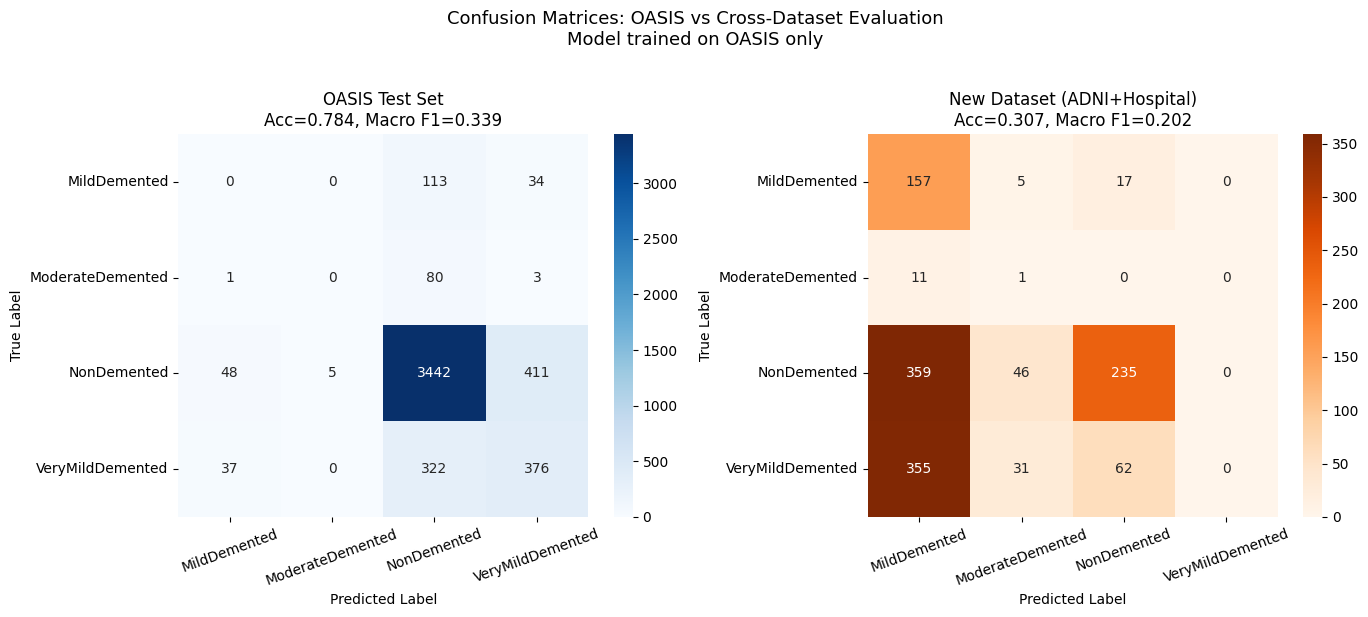

Saved comparison figure!


In [36]:
# Side-by-side confusion matrices for the report
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# OASIS confusion matrix
# Reload OASIS predictions from checkpoint
checkpoint = torch.load(os.path.join(SAVE_DIR, 'best_model.pt'))
model.load_state_dict(checkpoint['model_state_dict'])
_, test_acc, test_f1, oasis_preds, oasis_labels = evaluate(
    model, test_loader, criterion, device
)

cm_oasis = confusion_matrix(oasis_labels, oasis_preds)
sns.heatmap(cm_oasis, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0])
axes[0].set_title(f'OASIS Test Set\nAcc={test_acc:.3f}, Macro F1={test_f1:.3f}',
                  fontsize=12)
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
axes[0].tick_params(axis='x', rotation=20)

# Cross-dataset confusion matrix
cm_cross = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm_cross, annot=True, fmt='d', cmap='Oranges',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1])
axes[1].set_title(f'New Dataset (ADNI+Hospital)\nAcc={cross_acc:.3f}, Macro F1={cross_f1:.3f}',
                  fontsize=12)
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Confusion Matrices: OASIS vs Cross-Dataset Evaluation\n'
             'Model trained on OASIS only', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'confusion_matrices_comparison.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved comparison figure!")